In [12]:
from typing import TypedDict, List
from langgraph.graph import StateGraph

In [13]:
class AgentState(TypedDict):  # Our state schema
    values: List[int]
    name: str
    result: str
    operation: str  # New field to specify the operation to perform

In [14]:
def perform_operations(state: AgentState) -> AgentState:
    """This node performs multiple operations on the list of integers in the state and returns a new state with the result string updated."""
    if state["operation"] == "+":
        state["result"] = f"Hello {state['name']}, the sum of your values is {sum(state['values'])}."
    elif state["operation"] == "*":
        product = 1
        for value in state["values"]:
            product *= value
        state["result"] = f"Hello {state['name']}, the product of your values is {product}."
    else:
        state["result"] = f"Hello {state['name']}, unknown operation '{state['operation']}'."
    return state

In [15]:
graph = StateGraph(AgentState)

graph.add_node("operation_processor", perform_operations)

graph.set_entry_point("operation_processor")
graph.set_finish_point("operation_processor")

app = graph.compile()


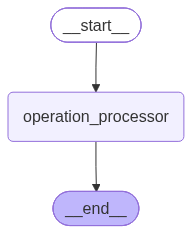

In [16]:
from IPython.display import display, Image
display(Image(app.get_graph().draw_mermaid_png()))

In [18]:
# Addition
result1 = app.invoke({
    "values": [1, 2, 3, 4],
    "name": "Alice",
    "operation": "+"
})

print(result1)


# Multiplication
result2 = app.invoke({
    "values": [1, 2, 3, 4],
    "name": "Bob",
    "operation": "*"
})

print(result2)

{'values': [1, 2, 3, 4], 'name': 'Alice', 'result': 'Hello Alice, the sum of your values is 10.', 'operation': '+'}
{'values': [1, 2, 3, 4], 'name': 'Bob', 'result': 'Hello Bob, the product of your values is 24.', 'operation': '*'}
